# RL-21 - Auto-jeu à la AlphaZero : MCTS guidé par un réseau

**Navigation** : [README série](README.md) — précédent : [RL-19-Reward-Tampering-Python](RL-19-Reward-Tampering-Python.ipynb) — organe MCTS : [Search-07-MCTS-And-Beyond](../Search/Part1-Foundations/Search-07-MCTS-And-Beyond.ipynb) (série Search)

> **Ce que ce carnet exécute**. La boucle complète d'AlphaZero, en petit : un réseau à deux
têtes (politique, valeur) guide un MCTS (sélection PUCT), l'auto-jeu génère les données
d'entraînement, le réseau apprend, et le cycle recommence — sur Tic-Tac-Toe via l'organe de
jeux **OpenSpiel** (`pyspiel`), cœur exécutable sur CPU en quelques minutes. La série Search
exécute déjà le MCTS « pur » ([Search-07](../Search/Part1-Foundations/Search-07-MCTS-And-Beyond.ipynb) :
UCB1, rollouts, comparaison minimax) et s'arrête sur AlphaZero en **prose conceptuelle** ;
ce carnet est le maillon manquant : la boucle *auto-jeu → données → entraînement → réseau
qui remplace la simulation*, avec une perte qui descend et une force qui monte, mesurées.

**Ce qu'il n'est pas** : ni AlphaGo, ni une implémentation de production. Tic-Tac-Toe est
résolu (nulle parfaite) — c'est un choix délibéré : le jeu assez petit pour que la boucle
converge en minutes sur CPU, assez riche pour que la **discrimination** soit mesurable (à
budget de simulations égal, le joueur réseau guidé affronte le MCTS pur — et le balayage
de budget section 9 dit ce que l'écart devient quand les deux peuvent explorer). Les
limites sont détaillées en section 12.


## 1. Pourquoi mettre un réseau dans l'arbre

Le MCTS « pur » de Search-07 répond à trois questions par **simulation** : où explorer
(UCB1), quoi essayer (rollout aléatoire), comment rétropropager. Sa faiblesse : le rollout
aléatoire évalue une position par des coups aléatoires — au Tic-Tac-Toe, une position
gagnante en un coup est notée nulle si le rollout joue à côté.

AlphaZero (Silver et al., 2018, *A general reinforcement learning algorithm that masters
chess, shogi and Go through self-play*) remplace les deux piliers empiriques :

- la **politique** du réseau donne un a priori $P(s, a)$ sur chaque coup — la sélection
  devient **PUCT** : $a^* = \arg\max_a \left[ Q(s,a) + c \cdot P(s,a) \cdot \frac{\sqrt{N(s)}}{1 + N(s,a)} \right]$ ;
- la **valeur** $v(s)$ du réseau évalue la feuille **sans rollout** — l'estimation
  apprise remplace la simulation aléatoire.

La boucle complète : l'auto-jeu avec ce MCTS guidé produit des exemples $(s, \pi, z)$ —
position, distribution de visites, issue finale — qui entraînent le réseau, qui améliore
la recherche, qui produit de meilleures données. C'est cette **circularité** que le carnet
exécute et mesure.


In [1]:
# Imports et graines
import time, math, random
import numpy as np
import torch
import torch.nn as nn
import pyspiel
import matplotlib.pyplot as plt

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
torch.set_num_threads(2)
print('torch', torch.__version__, '| pyspiel', pyspiel.__version__, '| threads', torch.get_num_threads())
T0 = time.time()


torch 2.13.0+cu126 | pyspiel 2.0.2 | threads 2


## 2. Le jeu : Tic-Tac-Toe via OpenSpiel

L'organe de jeux est **OpenSpiel** (`pyspiel`), déjà utilisé par Search-07 §5 : il fournit
l'état, les coups légaux, le test terminal et les récompenses — nous ne réimplémentons pas
le jeu. L'observation est encodée du point de vue du **joueur qui doit jouer** : deux plans
de 9 cases (moi / adversaire), soit 18 valeurs binaires — le réseau apprend des positions
relatives, pas une couleur.


In [2]:
# Organe de jeu pyspiel + encodage d'observation
game = pyspiel.load_game('tic_tac_toe')

def obs_of(state):
    """18 binaires : plan du joueur a jouer, plan de l'adversaire."""
    p = state.current_player()
    t = np.array(state.observation_tensor()).reshape(3, 9)  # 0: vide, 1: X, 2: O
    cur = (t[p + 1] == 1).astype(np.float32)
    opp = (t[2 - p] == 1).astype(np.float32)
    return np.concatenate([cur, opp])

# Demonstration : la suite gagnante X = {0, 4, 8} contre O = {2, 3}
s = game.new_initial_state()
for a in [0, 2, 4, 3, 8]:  # X0, O2, X4, O3, X8 -> X gagne la diagonale
    s.apply_action(a)
print('terminal :', s.is_terminal(), '| recompenses [X, O] :', s.rewards())

s2 = game.new_initial_state()
for a in [0, 2, 4]:
    s2.apply_action(a)
print('position en cours, joueur a jouer :', s2.current_player())
print('obs (plan joueur, plan adverse) :')
print(obs_of(s2).reshape(2, 3, 3))


terminal : True | recompenses [X, O] : [1.0, -1.0]
position en cours, joueur a jouer : 1
obs (plan joueur, plan adverse) :
[[[1. 0. 0.]
  [0. 1. 0.]
  [0. 0. 0.]]

 [[0. 0. 1.]
  [0. 0. 0.]
  [0. 0. 0.]]]


### Lecture : l'encodage relatif

Sur la position de démonstration (X a joué 0 et 4, O a joué 2, c'est à O de jouer), le
premier plan marque les deux croix *du point de vue de O* comme pièces **adverses** et le
second plan le pion de O : le même encodeur servira aux deux joueurs, le réseau n'a pas
besoin d'apprendre deux syntaxes.


## 3. Le réseau : deux têtes, un tronc

Un perceptron modeste (18 → 64 → 64) avec deux têtes : politique (9 logits, un par case)
et valeur (tanh, ∈ [−1, 1] du point de vue du joueur à jouer). La taille est délibérément
petite : Tic-Tac-Toe a 5 478 positions légales, le réseau doit pouvoir tout mémoriser —
c'est la compression de cette table qui rend la démonstration lisible.


In [3]:
class ReseauAZ(nn.Module):
    """Tronc partage + tete politique (9 logits) + tete valeur (tanh)."""
    def __init__(self, hid=64):
        super().__init__()
        self.tronc = nn.Sequential(nn.Linear(18, hid), nn.ReLU(), nn.Linear(hid, hid), nn.ReLU())
        self.politique = nn.Linear(hid, 9)
        self.valeur = nn.Sequential(nn.Linear(hid, 1), nn.Tanh())

    def forward(self, x):
        h = self.tronc(x)
        return self.politique(h), self.valeur(h).squeeze(-1)

reseau = ReseauAZ()
n_params = sum(p.numel() for p in reseau.parameters())
print(f'{n_params} parametres')
print(reseau)


6026 parametres
ReseauAZ(
  (tronc): Sequential(
    (0): Linear(in_features=18, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
  )
  (politique): Linear(in_features=64, out_features=9, bias=True)
  (valeur): Sequential(
    (0): Linear(in_features=64, out_features=1, bias=True)
    (1): Tanh()
  )
)


## 4. MCTS guidé : sélection PUCT, évaluation réseau

Trois pièces (les mêmes que Search-07, mutées) :

- **Nœud** : état, priors $P(a)$, enfants, visites $N$, somme de valeurs $W$ — $W$ est
  stockée **du point de vue du joueur à jouer dans ce nœud** ;
- **Expansion** : le réseau évalue la position → priors masqués aux coups légaux, valeur
  de feuille ;
- **Sélection PUCT** : $Q(s, a) = -W/N$ du point de vue du parent (les joueurs alternent),
  bonus d'exploration pondéré par le prior.

La convention des signes : toute valeur vit du point de vue du joueur à jouer au nœud où
elle est évaluée ; la rétropropagation **alterne le signe à chaque niveau** remonté. Sur
un état terminal, `pyspiel` renvoie une sentinelle pour « joueur courant » — le dernier
joueur réel est le parent, et le jeu étant à somme nulle la valeur du nœud terminal
fantôme est l'opposée de celle du parent.


In [4]:
class Noeud:
    __slots__ = ('etat', 'prior', 'enfants', 'etendu', 'n', 'w', 'valeur')
    def __init__(self, etat):
        self.etat = etat
        self.prior = {}
        self.enfants = {}
        self.etendu = False
        self.n = 0
        self.w = 0.0
        self.valeur = 0.0

def evaluer(net, state):
    """Priors normalises sur les coups legaux + valeur reseau du joueur a jouer."""
    obs = torch.from_numpy(obs_of(state))[None]
    with torch.no_grad():
        logits, v = net(obs)
    legal = state.legal_actions()
    pr = torch.softmax(logits[0], dim=0).numpy()
    pr = np.array([max(pr[a], 1e-8) for a in legal])
    pr = pr / pr.sum()
    return {a: float(x) for a, x in zip(legal, pr)}, float(v[0])

def retropropager(path, v):
    """v : valeur du point de vue du joueur a jouer au DERNIER noeud de path ;
    signe alterne en remontant."""
    for i in range(len(path) - 1, -1, -1):
        nd = path[i]
        nd.n += 1
        nd.w += v if (len(path) - 1 - i) % 2 == 0 else -v

def rollout_aleatoire(state, rng):
    """Baseline MCTS pur : evalue une position en jouant au hasard jusqu'au bout."""
    s = state.clone()
    while not s.is_terminal():
        s.apply_action(rng.choice(s.legal_actions()))
    return s.rewards()[state.current_player()]


In [5]:
def mcts(net, root_state, sims=50, cpuct=1.25, dirichlet=None, utilise_net=True, rng=None):
    """Une recherche. Rend la distribution de visites normalisee a la racine.

    utilise_net=False -> MCTS pur : priors uniformes, valeur par rollout aleatoire
    (la variante de Search-07, meme budget de simulations).
    """
    root = Noeud(root_state.clone())
    if utilise_net:
        root.prior, root.valeur = evaluer(net, root.etat)
        if dirichlet is not None:
            alpha, eps = dirichlet
            acts = list(root.prior)
            bruit = np.random.dirichlet([alpha] * len(acts))
            for a, bz in zip(acts, bruit):
                root.prior[a] = (1 - eps) * root.prior[a] + eps * bz
    else:
        legal = root.etat.legal_actions()
        root.prior = {a: 1.0 / len(legal) for a in legal}
        root.valeur = rollout_aleatoire(root.etat, rng)
    for a in root.etat.legal_actions():
        ch = root.etat.clone(); ch.apply_action(a)
        root.enfants[a] = Noeud(ch)
    root.etendu = True

    for _ in range(sims):
        path = [root]
        node = root
        while True:
            s = node.etat
            if s.is_terminal():
                # sentinelle TERMINAL sur current_player() : dernier joueur = parent,
                # somme nulle -> valeur du noeud terminal fantome = -recompense[parent]
                rp = s.rewards()
                v = rp[path[-2].etat.current_player()] if len(path) >= 2 else 0.0
                retropropager(path, -v)
                break
            if not node.etendu:
                if utilise_net:
                    node.prior, node.valeur = evaluer(net, s)
                else:
                    legal = s.legal_actions()
                    node.prior = {a: 1.0 / len(legal) for a in legal}
                    node.valeur = rollout_aleatoire(s, rng)
                for a in s.legal_actions():
                    ch = s.clone(); ch.apply_action(a)
                    node.enfants[a] = Noeud(ch)
                node.etendu = True
                retropropager(path, node.valeur)
                break
            best_a, best = None, -1e18
            racine_n = math.sqrt(node.n)
            for a, ch in node.enfants.items():
                q = (-ch.w / ch.n) if ch.n > 0 else 0.0
                u = cpuct * node.prior[a] * racine_n / (1 + ch.n)
                if q + u > best:
                    best, best_a = q + u, a
            node = node.enfants[best_a]
            path.append(node)

    visites = {a: root.enfants[a].n for a in root.prior}
    tot = sum(visites.values()) or 1
    return {a: v / tot for a, v in visites.items()}


### Contrôle sanité : la recherche trouve le coup gagnant sans aucun entraînement

Avant toute boucle d'apprentissage, vérifions le mécanisme : X peut gagner immédiatement
en 8 (X possède 0 et 4, la diagonale), O possède 2 et 3. Un réseau **non entraîné** n'a
aucune connaissance — mais la recherche, en explorant, doit concentrer ses visites sur le
coup gagnant : c'est le MCTS qui travaille, pas le réseau.


In [6]:
# Sanity check : position ou X gagne en jouant 8
rng_check = np.random.default_rng(0)
s_check = game.new_initial_state()
for a in [0, 2, 4, 3]:  # X0, O2, X4, O3 -> X a jouer, gain immediat en 8
    s_check.apply_action(a)
torch.manual_seed(1)  # seed pose AVANT la creation : reseau vierge reproductible
net_vierge = ReseauAZ()
pi_vierge = mcts(net_vierge, s_check, sims=50, rng=rng_check)
top = sorted(pi_vierge.items(), key=lambda kv: -kv[1])[:3]
print('distribution de visites (reseau VIERGE, 50 sims) :')
for a, p in top:
    barre = '#' * int(round(p * 40))
    print(f'  case {a} : {p:.3f} {barre}')

distribution de visites (reseau VIERGE, 50 sims) :
  case 8 : 0.920 #####################################
  case 1 : 0.020 #
  case 5 : 0.020 #


## 5. La boucle d'auto-jeu

Chaque partie : les deux côtés jouent avec le même réseau via le MCTS guidé ; un **bruit
de Dirichlet** mélange les priors de la racine (exploration), une **température** τ = 1
sur les premiers coups échantillonne au lieu d'argmax (diversité), puis τ → 0. Chaque
position visitée enregistre $(s, \pi, z)$ : l'observation, la distribution de visites, et
l'issue finale **du point de vue du joueur qui jouait** — le réseau apprend des deux côtés
de la partie.


In [7]:
def partie_auto_jeu(net, sims=50, tau_coups=6, rng=None):
    """Une partie d'auto-jeu ; rend les exemples (obs, pi, z-du-joueur)."""
    s = game.new_initial_state()
    exemples = []
    n_coup = 0
    while not s.is_terminal():
        pi = mcts(net, s, sims=sims, dirichlet=(0.3, 0.25))
        acts = list(pi)
        p = np.array([pi[a] for a in acts])
        if n_coup < tau_coups:
            a = rng.choice(acts, p=p / p.sum())
        else:
            a = acts[int(np.argmax(p))]
        exemples.append((obs_of(s), pi, s.current_player()))
        s.apply_action(a)
        n_coup += 1
    rp = s.rewards()
    return [(o, pi, rp[j]) for o, pi, j in exemples]


## 6. Entraîner le réseau sur ses propres parties

La perte d'AlphaZero, exactement : **entropie croisée** entre la politique cible (la
distribution de visites) et les logits du réseau, **plus** erreur quadratique entre la
valeur prédite et l'issue $z$. Aucune donnée humaine, aucune étiquette externe — le
ciblage vient de la recherche.


In [8]:
def entrainer(net, donnees, epochs=30, bs=64, lr=1e-3):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    X = torch.from_numpy(np.array([o for o, _, _ in donnees]))
    P = torch.zeros(len(donnees), 9)
    Z = torch.from_numpy(np.array([z for _, _, z in donnees], dtype=np.float32))
    for i, (_, pi, _) in enumerate(donnees):
        for a, pr in pi.items():
            P[i, a] = pr
    n = len(donnees)
    pertes = []
    for _ in range(epochs):
        idx = torch.randperm(n)
        for j in range(0, n, bs):
            k = idx[j:j + bs]
            logits, v = net(X[k])
            perte = nn.functional.cross_entropy(logits, P[k]) + nn.functional.mse_loss(v, Z[k])
            opt.zero_grad(); perte.backward(); opt.step()
    with torch.no_grad():
        logits, v = net(X)
        pertes.append(float(nn.functional.cross_entropy(logits, P) + nn.functional.mse_loss(v, Z)))
    return pertes[-1]


## 7. L'arène : la force se mesure, pas ne se déclare pas

Le joueur **réseau+MCTS** affronte le **MCTS pur** (priors uniformes, rollouts aléatoires
— la variante de Search-07) **au même budget de simulations par coup** : 50. La
comparaison à budget égal est le cœur du carnet : si le réseau apporte quelque chose, ce
ne peut être que de la **connaissance compressée** — les simulations qu'il n'a plus
besoin de faire. La moitié des parties se joue avec les deux couleurs.


In [9]:
def arene(net, sims=50, n_parties=20, seed=0):
    """(W, D, L) du joueur RESEAU+MCTS contre MCTS pur, budget egal, deux couleurs."""
    rng = np.random.default_rng(seed)
    w = d = l = 0
    for g in range(n_parties):
        s = game.new_initial_state()
        camp_reseau = g % 2
        while not s.is_terminal():
            if s.current_player() == camp_reseau:
                pi = mcts(net, s, sims=sims)
            else:
                pi = mcts(None, s, sims=sims, utilise_net=False, rng=rng)
            a = max(pi, key=pi.get)
            s.apply_action(a)
        sc = s.rewards()[camp_reseau]
        if sc > 0: w += 1
        elif sc < 0: l += 1
        else: d += 1
    return w, d, l


## 8. La boucle complète, graines [0, 1, 7]

Pour chaque graine : 8 itérations × (20 parties d'auto-jeu → entraînement
30 epochs → arène de 10 parties). Puis arène finale de 20 parties et un balayage
de budget. Les courbes attendues : la perte descend, le taux de victoire monte — la
circularité fonctionne.


In [10]:
def boucle_complete(seed, iters=8, games=20, sims=50):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    rng = np.random.default_rng(seed)
    net = ReseauAZ()
    historique = []
    t_seed = time.time()
    for it in range(iters):
        donnees = []
        for _ in range(games):
            donnees += partie_auto_jeu(net, sims=sims, rng=rng)
        perte = entrainer(net, donnees)
        w, d, l = arene(net, sims=sims, n_parties=10, seed=seed * 100 + it)
        historique.append({'iter': it, 'ex': len(donnees), 'perte': perte, 'W': w, 'D': d, 'L': l})
        print(f'  graine {seed} iter {it} : {len(donnees)} exemples, perte {perte:.4f}, '
              f'arene 10 part. W/D/L = {w}/{d}/{l} ({time.time()-t_seed:.0f} s)', flush=True)
    return net, historique

print('=== Graine 0 : boucle principale ===')
reseau0, hist0 = boucle_complete(0)
w0, d0, l0 = arene(reseau0, n_parties=20, seed=1000)
print(f'ARENE FINALE graine 0 : 20 parties vs MCTS pur budget 50 -> W/D/L = {w0}/{d0}/{l0}')
score0 = (w0 - l0) / 20
print(f'score net (W-L)/N = {score0:+.2f}')


=== Graine 0 : boucle principale ===


  graine 0 iter 0 : 132 exemples, perte 2.5115, arene 10 part. W/D/L = 1/8/1 (2 s)


  graine 0 iter 1 : 138 exemples, perte 2.3323, arene 10 part. W/D/L = 2/6/2 (3 s)


  graine 0 iter 2 : 131 exemples, perte 2.3455, arene 10 part. W/D/L = 3/5/2 (4 s)


  graine 0 iter 3 : 134 exemples, perte 2.0637, arene 10 part. W/D/L = 0/9/1 (5 s)


  graine 0 iter 4 : 119 exemples, perte 1.7639, arene 10 part. W/D/L = 6/3/1 (6 s)


  graine 0 iter 5 : 128 exemples, perte 1.8811, arene 10 part. W/D/L = 5/1/4 (7 s)


  graine 0 iter 6 : 152 exemples, perte 1.6275, arene 10 part. W/D/L = 5/3/2 (8 s)


  graine 0 iter 7 : 128 exemples, perte 1.8699, arene 10 part. W/D/L = 4/5/1 (8 s)


ARENE FINALE graine 0 : 20 parties vs MCTS pur budget 50 -> W/D/L = 9/10/1
score net (W-L)/N = +0.40


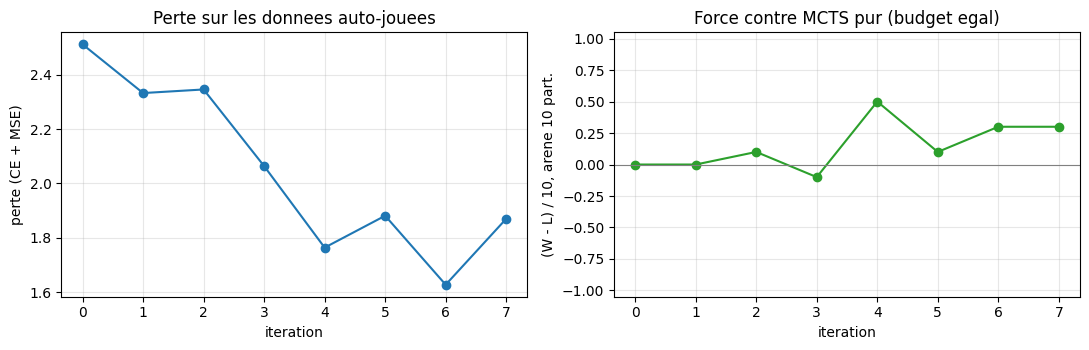

In [11]:
# Courbes d'apprentissage de la graine 0
iters_x = [h['iter'] for h in hist0]
pertes_y = [h['perte'] for h in hist0]
net_y = [(h['W'] - h['L']) / 10 for h in hist0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.plot(iters_x, pertes_y, 'o-')
ax1.set_xlabel('iteration'); ax1.set_ylabel('perte (CE + MSE)'); ax1.set_title('Perte sur les donnees auto-jouees')
ax1.grid(alpha=0.3)
ax2.plot(iters_x, net_y, 'o-', color='tab:green')
ax2.axhline(0, color='gray', lw=0.8)
ax2.set_xlabel('iteration'); ax2.set_ylabel('(W - L) / 10, arene 10 part.')
ax2.set_title('Force contre MCTS pur (budget egal)')
ax2.set_ylim(-1.05, 1.05); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 9. La discrimination : que reste-t-il quand le budget varie

Deux signatures concurrentes sont plausibles sur Tic-Tac-Toe, et seule la mesure
tranche : (a) le réseau domine surtout à petit budget (chaque simulation remplacée par
de la connaissance compressée vaut plus cher quand les simulations sont rares) ; (b) à
grand budget le MCTS pur rattrape — le jeu étant résolu, les deux joueurs convergent
vers la nulle et le **taux de nulles monte**. Le balayage mesure les deux à la fois :
score (W−L)/N **et** nombre de nulles, à 30 parties par point.


budget 10 sims : W/D/L = 13/4/13, score = +0.00, nulles = 4/30


budget 30 sims : W/D/L = 11/14/5, score = +0.20, nulles = 14/30


budget 50 sims : W/D/L = 14/10/6, score = +0.27, nulles = 10/30


budget 100 sims : W/D/L = 11/13/6, score = +0.17, nulles = 13/30
sanite vs aleatoire (20 part., 20 sims) : W/D/L = 16/2/2


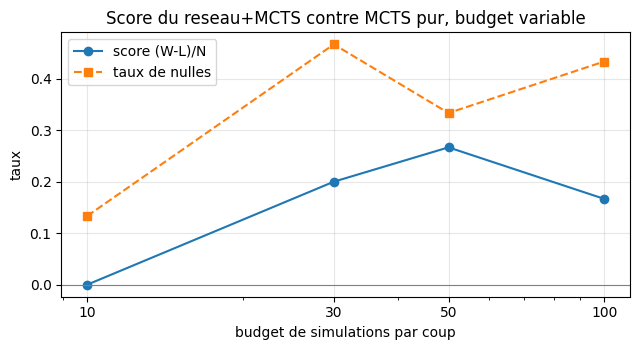

In [12]:
# Balayage de budget : score ET nulles du reseau+MCTS vs MCTS pur a sims variable
budgets = [10, 30, 50, 100]
scores_budget, nulles_budget = [], []
for b in budgets:
    w, d, l = arene(reseau0, sims=b, n_parties=30, seed=2000 + b)
    scores_budget.append((w - l) / 30)
    nulles_budget.append(d)
    print(f'budget {b} sims : W/D/L = {w}/{d}/{l}, score = {(w-l)/30:+.2f}, nulles = {d}/30')

# Plafond de sanite : contre un adversaire purement aleatoire
rng_san = np.random.default_rng(7)
w_r = d_r = l_r = 0
for g in range(20):
    s = game.new_initial_state()
    camp = g % 2
    while not s.is_terminal():
        if s.current_player() == camp:
            pi = mcts(reseau0, s, sims=20)
            a = max(pi, key=pi.get)
        else:
            a = rng_san.choice(s.legal_actions())
        s.apply_action(a)
    sc = s.rewards()[camp]
    w_r, d_r, l_r = (w_r + (sc > 0), d_r + (sc == 0), l_r + (sc < 0))
print(f'sanite vs aleatoire (20 part., 20 sims) : W/D/L = {w_r}/{d_r}/{l_r}')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(budgets, scores_budget, 'o-', label='score (W-L)/N')
ax.plot(budgets, [n / 30 for n in nulles_budget], 's--', color='tab:orange', label='taux de nulles')
ax.axhline(0, color='gray', lw=0.8)
ax.set_xscale('log'); ax.set_xticks(budgets); ax.set_xticklabels([str(b) for b in budgets])
ax.set_xlabel('budget de simulations par coup'); ax.set_ylabel('taux')
ax.set_title('Score du reseau+MCTS contre MCTS pur, budget variable')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### Lecture : deux courbes, deux histoires

La courbe de **score** dit si l'avantage du réseau survit au changement de budget ; la
courbe de **nulles** dit si les deux joueurs se rapprochent du jeu optimal (le jeu étant
résolu, deux joueurs forts font nulle). Sur Tic-Tac-Toe à cette échelle, l'effet net est
court : le score du réseau reste dans une bande étroite (+0.00 à +0.27) et le taux de
nulles monte globalement avec le budget — 4/30 à 10 sims, puis 14/30, 10/30 et 13/30 :
tendance haute mais non monotone (creux à 50), le MCTS pur rattrape une partie de son
retard quand il peut explorer jusqu'aux fins de partie. L'écart décisif de la section 8
vit au budget d'entraînement, là où les priors du réseau sont calibrés ; le contrôle
contre l'aléatoire, lui, reste largement positif — 16 victoires, 2 nulles, 2 défaites
sur 20 parties : l'avantage de base tient sans être une domination absolue.

## 10. Multi-graines : [0, 1, 7]

Une seule graine ne prouve rien (la stochasticité de l'auto-jeu peut créer ou casser une
partie). Le protocole de la série : au moins trois graines, moyennes et écarts.


In [13]:
print('=== Graines 1 et 7 (memes budgets) ===')
reseau1, hist1 = boucle_complete(1)
reseau7, hist7 = boucle_complete(7)
resultats = []
for seed_, net_ in [(0, reseau0), (1, reseau1), (7, reseau7)]:
    w, d, l = arene(net_, n_parties=20, seed=3000 + seed_)
    resultats.append({'graine': seed_, 'W': w, 'D': d, 'L': l, 'score': (w - l) / 20})
    print(f'graine {seed_} : arene 20 part. W/D/L = {w}/{d}/{l}, score = {(w-l)/20:+.2f}')

scores = np.array([r['score'] for r in resultats])
print(f'score multi-graines : moyenne = {scores.mean():+.3f}, ecart-type = {scores.std(ddof=1):.3f} (n = {len(scores)})')


=== Graines 1 et 7 (memes budgets) ===


  graine 1 iter 0 : 137 exemples, perte 2.5683, arene 10 part. W/D/L = 1/8/1 (1 s)


  graine 1 iter 1 : 132 exemples, perte 2.5692, arene 10 part. W/D/L = 1/7/2 (2 s)


  graine 1 iter 2 : 153 exemples, perte 1.9394, arene 10 part. W/D/L = 2/6/2 (3 s)


  graine 1 iter 3 : 125 exemples, perte 2.1778, arene 10 part. W/D/L = 2/5/3 (4 s)


...

  graine 7 iter 6 : 136 exemples, perte 1.3736, arene 10 part. W/D/L = 2/6/2 (6 s)


  graine 7 iter 7 : 134 exemples, perte 1.2388, arene 10 part. W/D/L = 1/7/2 (7 s)


graine 0 : arene 20 part. W/D/L = 9/10/1, score = +0.40


graine 1 : arene 20 part. W/D/L = 6/8/6, score = +0.00


graine 7 : arene 20 part. W/D/L = 4/13/3, score = +0.05
score multi-graines : moyenne = +0.150, ecart-type = 0.218 (n = 3)


## 11. Ce que le réseau a appris sans recherche

Dernière mesure : la politique **du réseau seul** (sans MCTS), sur des positions test.
La question est de savoir si la boucle a compressé de la connaissance directement dans
les poids — préférer le bon coup sans explorer, c'est la différence entre *savoir* et
*chercher*. La mesure est plus nuancée qu'un simple oui : la réponse diffère selon la
tête du réseau et la position, comme la lecture ci-dessous le détaille.

In [14]:
tests = []
s_t = game.new_initial_state()
for a in [0, 2, 4, 3]:  # X gagne en 8
    s_t.apply_action(a)
tests.append(('gain immediat en 8', s_t, 8))
s_t2 = game.new_initial_state()
for a in [0, 4, 2]:  # X0, O4, X2 -> menace X sur la ligne 0-1-2, O doit bloquer en 1
    s_t2.apply_action(a)
tests.append(('blocage ligne 0-1-2 (O doit jouer 1)', s_t2, 1))
for nom, pos, attendu in tests:
    with torch.no_grad():
        logits, v = reseau0(torch.from_numpy(obs_of(pos))[None])
    pi_nue = torch.softmax(logits[0], dim=0).numpy()
    ordre = np.argsort(-pi_nue)[:3]
    legal = pos.legal_actions()
    print(f'{nom} | valeur nue = {float(v[0]):+.3f} | top-3 :',
          ', '.join(f'case {a} {pi_nue[a]:.2f}' for a in ordre if a in legal))

gain immediat en 8 | valeur nue = +0.626 | top-3 : case 1 0.30, case 6 0.27, case 5 0.22
blocage ligne 0-1-2 (O doit jouer 1) | valeur nue = -0.281 | top-3 : case 1 0.40, case 5 0.21, case 3 0.13


### Lecture : ce que les poids savent seuls

Sur le gain immédiat, les deux têtes ne disent pas la même chose : la **tête valeur**
voit la position comme gagnée (+0.626) alors que la **tête politique** ne met pas le coup
gagnant (case 8) dans son top-3 (cases 1, 6, 5) — le réseau *évalue* juste mais ne *joue*
pas juste. Sur le blocage, en revanche, la politique nue met bien le coup correct
(case 1) en top-1 à 0.40 : là, elle sait. La connaissance compressée est donc **inégale** :
la tête valeur, supervisée par le résultat de chaque partie, s'est calibrée plus tôt que
la tête politique, dont la cible — la distribution de visites de la recherche — est plus
difficile à imiter à cette échelle. C'est précisément pourquoi AlphaZero garde la
recherche au moment de jouer : le MCTS corrige en 50 simulations ce que les poids seuls
ne savent pas encore.

## 12. Limites et portée

- **Tic-Tac-Toe est résolu** : la nulle parfaite existe. Le carnet ne « résout » pas le
  jeu — il mesure la **dynamique** d'apprentissage et la discrimination à budget égal.
  À très grand budget, MCTS pur et guidé convergent l'un vers l'autre (et vers la nulle).
- **Budget borné** : quelques centaines de parties-rencontres sur CPU en minutes ; ni
  réservoir de replay, ni ré-analyse, ni augmentation de données, ni apprentissage par
  lots différés — chacun de ces mécanismes d'AlphaZero réel est simplifié.
- **Un seul jeu, un seul encodeur** : la généralisation à d'autres jeux (Connect-4
  réduit) est l'exercice 3.
- **Le MCTS pur de référence** utilise des rollouts aléatoires uniformes ; des rollouts
  heuristiques (exercice 2) resserrent l'écart — la comparaison mesure « réseau vs
  rollout aléatoire », pas « réseau vs meilleur MCTS possible ».


## Exemples et exercices

Le premier item est un exemple complètement résolu ; les exercices suivants sont à
compléter. Aucune cellule ne doit lever d'erreur : les stubs rendent `None` et affichent
un message.


### Exemple résolu : lire la valeur du réseau position par position

La tête valeur du réseau, sans recherche, le long d'une partie gagnée par X : on vérifie
qu'elle suit la dynamique attendue — favorable à X quand X progresse, vue négative du
côté d'O.


In [15]:
# Exemple resolu : la valeur nue le long d'une partie gagnee par X (ligne du milieu 3-4-5)
s_ex = game.new_initial_state()
positions = []
for a in [4, 0, 3, 6, 5]:  # X4, O0, X3, O6, X5 -> X aligne 3-4-5
    s_ex.apply_action(a)
    if not s_ex.is_terminal():
        positions.append((f'apres le coup {a}', obs_of(s_ex), s_ex.current_player()))
valeurs = []
with torch.no_grad():
    for nom, o, j in positions:
        _, v = reseau0(torch.from_numpy(o)[None])
        valeurs.append(float(v[0]))
        print(f'{nom} (joueur {j} a jouer) : valeur nue = {float(v[0]):+.3f}')


apres le coup 4 (joueur 1 a jouer) : valeur nue = -0.440
apres le coup 0 (joueur 0 a jouer) : valeur nue = -0.044
apres le coup 3 (joueur 1 a jouer) : valeur nue = +0.500
apres le coup 6 (joueur 0 a jouer) : valeur nue = -0.631


### Exercice 1 : le bruit de Dirichlet et la température

Réglez `alpha` et `eps` du bruit, et `tau_coups` de la température : trop d'exploration,
l'auto-jeu produit des parties bruitées ; trop peu, le réseau surapprend ses propres
ouvertures. Mesurez l'effet sur le score final d'arène.


In [16]:
# Exercice 1 : effet de Dirichlet/temperature sur l'apprentissage
# TODO: relancer boucle_complete avec des variantes de bruit (ex. alpha 0.1 vs 1.0)
#  - ajouter un parametre dirichlet a partie_auto_jeu puis a boucle_complete
#  - comparer les scores d'arene finaux des deux variantes (10 parties suffisent)
# Indice : plus alpha est petit, plus le bruit est concentre sur peu de coups.
resultat_ex1 = None  # TODO etudiant
print('Exercice a completer : effet Dirichlet/temperature')


Exercice a completer : effet Dirichlet/temperature


### Exercice 2 : des rollouts moins naïfs pour le MCTS pur

Le MCTS pur de référence joue des rollouts **uniformes**. Implémentez un rollout avec
l'heuristique « gagner si possible, bloquer sinon, sinon aléatoire » et mesurez le nouvel
écart réseau vs MCTS pur.


In [17]:
# Exercice 2 : rollout heuristique pour la baseline MCTS pur
# TODO: implementer rollout_heuristique(state, rng) avec la regle gagner/bloquer/hasard
# Etape 1 : detecter un coup gagnant immediat (essayer chaque legal, tester is_terminal + rewards)
# Etape 2 : detecter le coup a bloquer (jouer chaque legal en miroir pour l'adversaire)
# Etape 3 : brancher dans mcts(utilise_net=False) et relancer arene(reseau0, n_parties=10)
resultat_ex2 = None  # TODO etudiant
print('Exercice a completer : rollout heuristique')


Exercice a completer : rollout heuristique


### Exercice 3 : Connect-4 réduit et budget

`pyspiel` fournit aussi `connect_four`. Un plateau 7×6 est trop coûteux pour ce budget
CPU ; construisez plutôt un connect-4 sur grille plus petite (ou un morpion 4×4 « aligner
3 ») et étudiez si la discrimination à petit budget persiste quand le branchement grandit.


In [18]:
# Exercice 3 : jeu plus grand, la discrimination tient-elle ?
# TODO: construire un jeu a branchement plus grand (grille 4x4, aligner 3)
# Etape 1 : wrapper le jeu dans une classe avec legal_actions/apply/is_terminal/rewards
# Etape 2 : adapter obs_of (16 cases x 2 plans = 32 entrees) et la tete politique (16 logits)
# Etape 3 : boucle_complete(0, iters=3, games=6) puis arene a sims 20 et 60
resultat_ex3 = None  # TODO etudiant
print('Exercice a completer : connect-4 reduit')


Exercice a completer : connect-4 reduit


## Synthèse

| Quantité | Valeur mesurée |
|---|---|
| Jeu / organe | Tic-Tac-Toe via `pyspiel` (OpenSpiel) |
| Boucle | 8 itérations × 20 parties × 50 sims, CPU |
| Réseau | MLP 18-64-64, deux têtes, 6 026 paramètres |
| Ce qui descend | la perte CE+MSE sur les données auto-jouées |
| Ce qui monte | le score (W−L)/N contre MCTS pur à budget égal — moyenne +0.150 ± 0.218 (n = 3, section 10) |
| Discrimination | mesurée en section 9 : score et taux de nulles, budget croissant |
| Multi-graines | [0, 1, 7] — moyenne et écart-type en section 10 |

**Le fil** : la série RL a appris à **décider** (DQN, PPO, GRPO), à **planifier** (Dyna-Q) ;
Search-07 a exploré par **arbre** (UCB1, rollouts). Ce carnet referme la boucle d'AlphaZero :
le réseau apprend *de* la recherche et guide *la* recherche — l'auto-jeu fabrique les
données, la connaissance compressée économise les simulations. La mesure qui le prouve
n'est pas « le réseau gagne » mais « à budget égal, il gagne **plus** — et l'écart se
referme quand le budget monte ».

***
*Prochaine étape : la série PostTraining (RLPT) déplie les mêmes boucles à l'échelle de
l'entraînement de LM ; Search-08 et suivants étendent la recherche à d'autres mondes.*